# ResNet50 U-Net with the DEM, trained with FloodNet

Combines `unet_dem.ipynb` (RGB + DEM as a 4th channel) with `model_using_floodnet.ipynb` (FloodNet mosaics added to training).

- **Model:** same as `unet_dem.ipynb`. ResNet's `conv1_conv` gets a 4th (DEM) input that starts at zero; the rest of the encoder is frozen with ImageNet weights.
- **FloodNet has no DEM,** so its 4th channel is all zeros. Because the Houston DEM is centered per image, 0 means "average height", which looks like flat ground.
- **Houston tiles always keep their real DEM.** Only FloodNet tiles get the zero channel. (A known risk: the model could learn "flat DEM = FloodNet = mostly dry". Section 6 checks how much the model relies on the DEM.)
- **Checkpoint:** best Houston val loss, but only from epoch `MIN_EPOCH` on, so a lucky first epoch can't win. The last epoch is saved too.
- **Scored on:** the Houston test images (4, 5, 6, 7, 10, 11), with the cutoff picked on val image 12, the same as the other notebooks.

Weights are saved to `../outputs/unet_dem_floodnet.weights.h5` (best) and `../outputs/unet_dem_floodnet_last.weights.h5` (last epoch).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

sys.path.append("../scripts")
from dataset import get_tiles, SPLITS
import floodnet as fn

keras.utils.set_random_seed(42)   # same seed as the comparison runs
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1794168233.202959   49499 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
MAX_UNKNOWN = 1.0      # keep every Houston training tile, like the other notebooks
EPOCHS = 15
BATCH = 4
FLOODNET_WEIGHT = 1.0  # 1.0 = FloodNet tiles drawn in proportion to their count
DEM_SCALE = 20         # same as unet_dem.ipynb
MIN_EPOCH = 5          # don't keep a checkpoint from before this epoch

WEIGHTS_PATH = "../outputs/unet_dem_floodnet.weights.h5"
LAST_PATH = "../outputs/unet_dem_floodnet_last.weights.h5"

## 1. Load and prepare the data

Houston scenes are loaded one at a time and preprocessed right away (RGB through ResNet's `preprocess_input`, DEM times `DEM_SCALE`), so only one copy of the 4-channel training array (~2 GB) is in memory.

In [3]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess(x):
    # RGB 0-1 -> ResNet50 preprocessing; DEM (if there is one) scaled like unet_dem.ipynb
    rgb = preprocess_input(x[..., :3] * 255.0)
    dem = x[..., 3:] * DEM_SCALE if x.shape[-1] == 4 else np.zeros_like(rgb[..., :1])   # FloodNet: no DEM -> zeros
    return np.concatenate([rgb, dem], axis=-1).astype("float32")

def prepare_labels(y):
    return y.astype("float32")[..., None]   # (N, 256, 256) -> (N, 256, 256, 1)

def load_houston(images, **kwargs):
    X, y = [], []
    for i in images:
        Xi, yi = get_tiles([i], **kwargs)
        X.append(preprocess(Xi))
        y.append(yi)
        del Xi
    return np.concatenate(X), np.concatenate(y)

X_train_in, y_train = load_houston(SPLITS["train"], stride=128, max_unknown=MAX_UNKNOWN)
X_val_in, y_val = load_houston(SPLITS["val"])

X_test, y_test = get_tiles(SPLITS["test"])
X_test_rgb = X_test[..., :3].copy()   # for the plots
X_test_in = preprocess(X_test)
del X_test

_, y_fn_sample = fn.get_floodnet_mosaics(["train"], seed=0)
for name, y in [("Houston train", y_train), ("Houston val", y_val), ("Houston test", y_test), ("FloodNet mosaics/epoch", y_fn_sample)]:
    known = y[y != -1]
    print(f"{name:23} {len(y):5} tiles  labeled {(y != -1).mean():5.1%}  flood (of labeled) {known.mean():.1%}")
print("Houston training inputs:", X_train_in.shape, f"{X_train_in.nbytes / 1e9:.2f} GB")

Houston train            1972 tiles  labeled 76.3%  flood (of labeled) 55.7%
Houston val               110 tiles  labeled 80.0%  flood (of labeled) 51.3%
Houston test              287 tiles  labeled 51.5%  flood (of labeled) 76.0%
FloodNet mosaics/epoch     47 tiles  labeled 72.5%  flood (of labeled) 15.8%
Houston training inputs: (1972, 256, 256, 4) 2.07 GB


## 2. Loss and model

In [4]:
def masked_bce(y_true, y_pred):
    known = tf.cast(y_true != -1, "float32")        # 1 = labeled pixel, 0 = unknown
    y_true = tf.where(y_true == -1, 0.0, y_true)    # BCE only understands 0/1
    loss = keras.losses.binary_crossentropy(y_true, y_pred)[..., None]
    return tf.reduce_sum(loss * known) / tf.reduce_sum(known)   # average over labeled pixels only

In [5]:
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, Conv2DTranspose, Concatenate, Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50

def conv_block(x, num_filters):
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def decoder_block(x, skip_features, num_filters):
    x = Conv2DTranspose(num_filters, 2, strides=2, padding="same")(x)
    x = Concatenate()([x, skip_features])
    return conv_block(x, num_filters)

def build_resnet50_unet(input_shape):
    inputs = Input(input_shape)
    resnet50 = ResNet50(include_top=False, weights=None, input_tensor=inputs)

    # ImageNet weights only exist for 3 channels: copy them over, and give conv1 a 4th (DEM) input that starts at zero
    pretrained = ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    for layer, src in zip(resnet50.layers, pretrained.layers):
        weights = src.get_weights()
        if layer.name == "conv1_conv":
            kernel, bias = weights
            weights = [np.concatenate([kernel, np.zeros_like(kernel[:, :, :1])], axis=2), bias]
        layer.set_weights(weights)

    s1 = inputs                                          # 256
    s2 = resnet50.get_layer("conv1_relu").output         # 128
    s3 = resnet50.get_layer("conv2_block3_out").output   # 64
    s4 = resnet50.get_layer("conv3_block4_out").output   # 32
    b1 = resnet50.get_layer("conv4_block6_out").output   # 16

    d1 = decoder_block(b1, s4, 512)   # 32
    d2 = decoder_block(d1, s3, 256)   # 64
    d3 = decoder_block(d2, s2, 128)   # 128
    d4 = decoder_block(d3, s1, 64)    # 256

    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)
    return Model(inputs, outputs, name="ResNet50_U-Net"), resnet50

model, encoder = build_resnet50_unet((256, 256, 4))
encoder.trainable = False
encoder.get_layer("conv1_conv").trainable = True   # the only encoder layer that can learn from the DEM

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_bce, jit_compile=False)
print(model.input_shape, "->", model.output_shape)

I0000 00:00:1794168254.851745   49499 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5562 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:2b:00.0, compute capability: 8.6


(None, 256, 256, 4) -> (None, 256, 256, 1)


## 3. Train on Houston + FloodNet mosaics

Each epoch builds a new FloodNet mosaic arrangement (`seed=epoch`), mixes it with the Houston tiles, and applies the same flip/rotate augmentation as the other notebooks.

In [6]:
def augment(x, y):
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    x, y = tf.image.rot90(x, k), tf.image.rot90(y, k)
    flip = tf.random.uniform([]) < 0.5
    x = tf.cond(flip, lambda: tf.image.flip_left_right(x), lambda: x)
    y = tf.cond(flip, lambda: tf.image.flip_left_right(y), lambda: y)
    return x, y

def houston_tiles():
    for i in np.random.permutation(len(X_train_in)):
        yield X_train_in[i], y_train[i, ..., None].astype("float32")

TILE_SPEC = (tf.TensorSpec((256, 256, 4), tf.float32), tf.TensorSpec((256, 256, 1), tf.float32))
houston_ds = tf.data.Dataset.from_generator(houston_tiles, output_signature=TILE_SPEC)

with tf.device("/CPU:0"):
    val_ds = tf.data.Dataset.from_tensor_slices((X_val_in, prepare_labels(y_val))).batch(BATCH)

def make_train_ds(epoch):
    X_fn, y_fn = fn.get_floodnet_mosaics(["train"], seed=epoch)
    with tf.device("/CPU:0"):
        fn_ds = tf.data.Dataset.from_tensor_slices((preprocess(X_fn), prepare_labels(y_fn)))
        n_h, n_f = len(X_train_in), len(X_fn) * FLOODNET_WEIGHT
        mixed = tf.data.Dataset.sample_from_datasets(
            [houston_ds.repeat(), fn_ds.shuffle(len(X_fn)).repeat()],
            weights=[n_h / (n_h + n_f), n_f / (n_h + n_f)],
            seed=epoch,
        )
        steps = int(np.ceil((len(X_train_in) + len(X_fn)) / BATCH))
        ds = mixed.map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(2)
    return ds, steps

I0000 00:00:1794093968.174590   37861 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1794093973.483016   37936 cuda_dnn.cc:461] Loaded cuDNN version 92700


epoch  1/15  loss 0.3684  val_loss 0.1892


epoch  2/15  loss 0.3077  val_loss 0.2481


epoch  3/15  loss 0.2888  val_loss 0.3298


epoch  4/15  loss 0.2941  val_loss 0.2308


... (7 outputs left out)

epoch 12/15  loss 0.1383  val_loss 0.3013


epoch 13/15  loss 0.1408  val_loss 0.2572  (saved)


epoch 14/15  loss 0.1148  val_loss 0.2048  (saved)


epoch 15/15  loss 0.1264  val_loss 0.2213


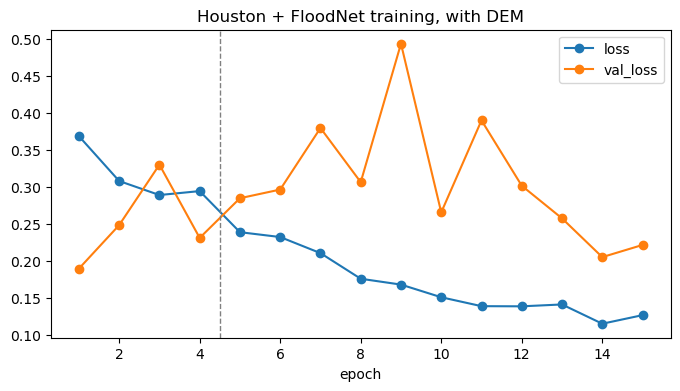

In [7]:
Path("../outputs").mkdir(exist_ok=True)

log = []
best_val = np.inf
for epoch in range(EPOCHS):
    train_ds, steps = make_train_ds(epoch)
    h = model.fit(train_ds, validation_data=val_ds, epochs=1, steps_per_epoch=steps, verbose=0)
    loss, val_loss = h.history["loss"][0], h.history["val_loss"][0]

    saved = epoch + 1 >= MIN_EPOCH and val_loss < best_val
    if saved:
        best_val = val_loss
        model.save_weights(WEIGHTS_PATH)
    log.append({"epoch": epoch + 1, "loss": loss, "val_loss": val_loss})
    print(f"epoch {epoch + 1:2}/{EPOCHS}  loss {loss:.4f}  val_loss {val_loss:.4f}" + ("  (saved)" if saved else ""))

model.save_weights(LAST_PATH)

log = pd.DataFrame(log)
ax = log.plot(x="epoch", y=["loss", "val_loss"], marker="o", figsize=(8, 4))
ax.axvline(MIN_EPOCH - 0.5, color="gray", ls="--", lw=1)
ax.set_title("Houston + FloodNet training, with DEM")
plt.show()

## 4. Pick the cutoff on Houston val

Tries several cutoffs on val image 12 and keeps the one with the best average of flood IoU and dry IoU, for both the best and the last-epoch weights.

In [7]:
CUTOFFS = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

def predict_probs(m, X, chunk=64):
    return np.concatenate([m.predict(X[i:i + chunk], batch_size=8, verbose=0)[..., 0] for i in range(0, len(X), chunk)])

def iou_scores(probs, y, cutoff):
    known = y != -1
    pred_flood = probs > cutoff
    true_flood, true_dry = y == 1, y == 0
    flood = np.sum(pred_flood & true_flood & known) / np.sum((pred_flood | true_flood) & known)
    dry = np.sum(~pred_flood & true_dry & known) / max(np.sum((~pred_flood | true_dry) & known), 1)
    return flood, dry, pred_flood[known].mean()

def pick_cutoff(probs, y):
    rows = []
    for cut in CUTOFFS:
        f, d, says = iou_scores(probs, y, cut)
        rows.append({"cutoff": cut, "flood IoU": f, "dry IoU": d, "mean IoU": (f + d) / 2, "says flood": says})
    table = pd.DataFrame(rows)
    return table.loc[table["mean IoU"].idxmax(), "cutoff"], table

results = {}
for name, path in [("best val", WEIGHTS_PATH), ("last epoch", LAST_PATH)]:
    model.load_weights(path)
    val_probs = predict_probs(model, X_val_in)
    cut, table = pick_cutoff(val_probs, y_val)
    results[name] = {"cutoff": cut, "test_probs": predict_probs(model, X_test_in)}
    print(f"{name}: best cutoff on val {cut}")
    display(table.round(3))

/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


I0000 00:00:1794168259.465864   49565 cuda_dnn.cc:461] Loaded cuDNN version 92700


best val: best cutoff on val 0.8


,cutoff,flood IoU,dry IoU,mean IoU,says flood
0,0.3,0.808,0.759,0.784,0.613
1,0.4,0.835,0.802,0.818,0.585
2,0.5,0.854,0.833,0.844,0.560
3,0.6,0.866,0.852,0.859,0.539
4,0.7,0.874,0.866,0.870,0.520
5,0.8,0.871,0.869,0.870,0.496


/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


last epoch: best cutoff on val 0.7


,cutoff,flood IoU,dry IoU,mean IoU,says flood
0,0.3,0.744,0.648,0.696,0.671
1,0.4,0.784,0.726,0.755,0.621
2,0.5,0.828,0.800,0.814,0.572
3,0.6,0.864,0.852,0.858,0.530
4,0.7,0.869,0.868,0.868,0.492
5,0.8,0.846,0.855,0.851,0.455


## 5. Test scores

Houston test images 4, 5 and 6 are 97-100% flood, so their dry IoU is close to 0 whatever the model does. Flood IoU is the more useful number for them; images 7 and 10 are the mixed scenes.

In [8]:
rows = []
for name, r in results.items():
    f, d, says = iou_scores(r["test_probs"], y_test, r["cutoff"])
    rows.append({"weights": name, "cutoff": r["cutoff"], "flood IoU": f, "dry IoU": d, "mean IoU": (f + d) / 2,
                 "says flood": says, "label says flood": (y_test[y_test != -1] == 1).mean()})
pd.DataFrame(rows).set_index("weights").round(3)

,cutoff,flood IoU,dry IoU,mean IoU,says flood,label says flood
weights,,,,,,
best val,0.8,0.720,0.454,0.587,0.635,0.76
last epoch,0.7,0.696,0.422,0.559,0.629,0.76


In [9]:
# Per Houston test image, best-val weights
model.load_weights(WEIGHTS_PATH)
CUTOFF = results["best val"]["cutoff"]
rows = []
for i in SPLITS["test"]:
    Xi, yi = get_tiles([i])
    pi = predict_probs(model, preprocess(Xi))
    f, d, says = iou_scores(pi, yi, CUTOFF)
    rows.append({"image": i, "flood IoU": f, "dry IoU": d, "mean IoU": (f + d) / 2, "says flood": says,
                 "label says flood": (yi[yi != -1] == 1).mean()})
pd.DataFrame(rows).set_index("image").round(3)

/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,flood IoU,dry IoU,mean IoU,says flood,label says flood
image,,,,,
4,0.821,0.116,0.469,0.803,0.976
5,0.948,0.100,0.524,0.943,0.994
6,0.479,0.000,0.239,0.479,1.000
7,0.634,0.687,0.661,0.536,0.370
10,0.849,0.778,0.813,0.569,0.641
11,0.822,0.416,0.619,0.759,0.858


## 6. Does the model use the DEM?

Scores the test images again with the DEM channel zeroed. If the scores barely change, the model is mostly ignoring elevation.

In [10]:
X_test_nodem = X_test_in.copy()
X_test_nodem[..., 3] = 0
probs_nodem = predict_probs(model, X_test_nodem)
del X_test_nodem

rows = []
for name, probs in [("with DEM", results["best val"]["test_probs"]), ("DEM zeroed", probs_nodem)]:
    f, d, says = iou_scores(probs, y_test, CUTOFF)
    rows.append({"input": name, "flood IoU": f, "dry IoU": d, "says flood": says})
pd.DataFrame(rows).set_index("input").round(3)

,flood IoU,dry IoU,says flood
input,,,
with DEM,0.72,0.454,0.635
DEM zeroed,0.69,0.357,0.682


## 7. Look at some predictions

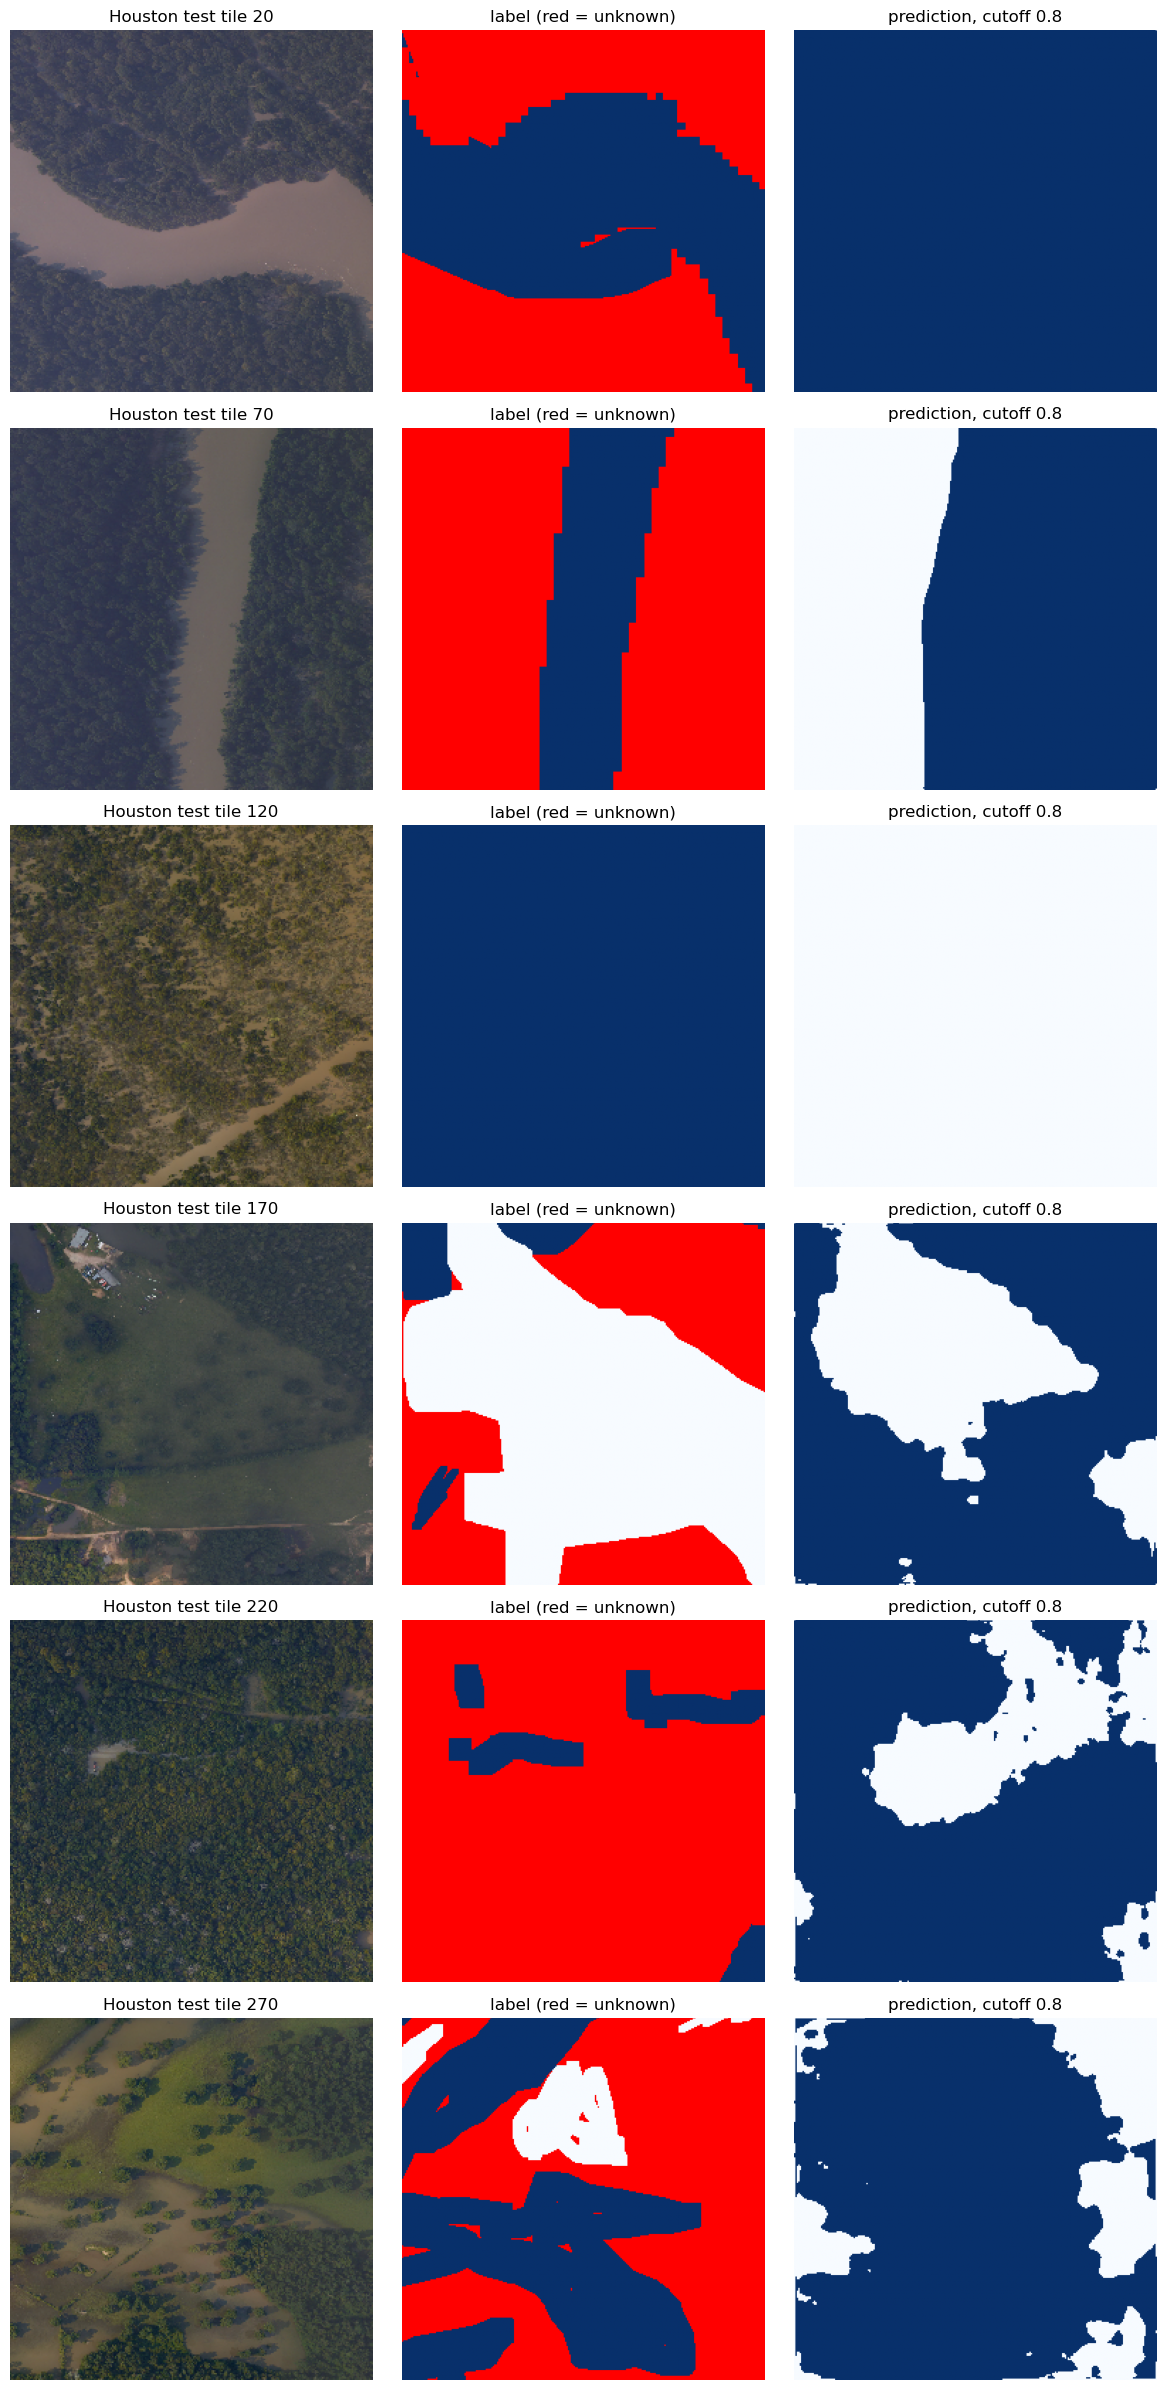

In [11]:
LABEL_CMAP = plt.get_cmap("Blues").copy()
LABEL_CMAP.set_bad("red")   # unknown (-1) pixels

test_probs = results["best val"]["test_probs"]
tiles = [20, 70, 120, 170, 220, 270]
fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_test_rgb[t]);                       axes[row, 0].set_title(f"Houston test tile {t}")
    axes[row, 1].imshow(np.ma.masked_equal(y_test[t], -1), cmap=LABEL_CMAP, vmin=0, vmax=1); axes[row, 1].set_title("label (red = unknown)")
    axes[row, 2].imshow(test_probs[t] > CUTOFF, cmap="Blues", vmin=0, vmax=1); axes[row, 2].set_title(f"prediction, cutoff {CUTOFF}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. FloodNet weight-transfer model

The **FloodNet weight-transfer model** starts from the trained FloodNet model instead of ImageNet.

It copies **every** weight from the trained RGB + FloodNet model (`model_using_floodnet.ipynb`) into the 4-channel model: encoder, decoder and output layer. The two layers that take the raw input tile, `conv1_conv` and the first conv of the last decoder block (through the `s1 = inputs` skip), get a 4th (DEM) input that starts at zero, so before any training this model gives exactly the same predictions as the RGB + FloodNet model. Training then only has to learn how to use the elevation on top.

(The FloodNet model's encoder was frozen during its training, so its encoder is still the ImageNet one. What carries over is its trained decoder.)

- Starts from `../outputs/unet_floodnet_rerun.weights.h5` (the RGB + FloodNet run with seed 42).
- Same trainable layers as above: decoder, output layer and `conv1_conv`. The rest of the encoder stays frozen.
- Lower learning rate (`1e-4`) and fewer epochs, because the decoder is already trained.
- Same data mix (Houston + FloodNet mosaics with a zero DEM), same checkpoint rule, same cutoff and test scoring.

Weights are saved to `../outputs/unet_dem_floodnet_transfer.weights.h5` (best) and `../outputs/unet_dem_floodnet_transfer_last.weights.h5` (last epoch).

In [12]:
FLOODNET_RGB_PATH = "../outputs/unet_floodnet_rerun.weights.h5"
TRANSFER_PATH = "../outputs/unet_dem_floodnet_transfer.weights.h5"
TRANSFER_LAST_PATH = "../outputs/unet_dem_floodnet_transfer_last.weights.h5"
TRANSFER_EPOCHS = 10
TRANSFER_LR = 1e-4
TRANSFER_MIN_EPOCH = 3

def build_rgb_unet():
    # same U-Net with 3 input channels, only used to load the FloodNet model's weights
    inputs = Input((256, 256, 3))
    resnet50 = ResNet50(include_top=False, weights=None, input_tensor=inputs)
    s2 = resnet50.get_layer("conv1_relu").output
    s3 = resnet50.get_layer("conv2_block3_out").output
    s4 = resnet50.get_layer("conv3_block4_out").output
    b1 = resnet50.get_layer("conv4_block6_out").output
    d4 = decoder_block(decoder_block(decoder_block(decoder_block(b1, s4, 512), s3, 256), s2, 128), inputs, 64)
    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)
    return Model(inputs, outputs)

keras.utils.set_random_seed(42)
rgb_model = build_rgb_unet()
rgb_model.load_weights(FLOODNET_RGB_PATH)

transfer_model, transfer_encoder = build_resnet50_unet((256, 256, 4))
assert len(transfer_model.layers) == len(rgb_model.layers)
# Two layers take the raw input tile, so they have one more input channel (the DEM) than in the RGB model:
# conv1_conv (start of the encoder) and the first conv of the last decoder block (the s1 = inputs skip).
# Both get a zero slice for the DEM, which is their last input channel, so the model starts out identical to the RGB one.
padded = []
for layer, src in zip(transfer_model.layers, rgb_model.layers):
    weights = src.get_weights()
    target = layer.get_weights()
    if weights and weights[0].shape != target[0].shape:
        kernel = weights[0]
        assert kernel.shape[2] + 1 == target[0].shape[2], (layer.name, kernel.shape, target[0].shape)
        weights = [np.concatenate([kernel, np.zeros_like(kernel[:, :, :1])], axis=2)] + weights[1:]
        padded.append(layer.name)
    layer.set_weights(weights)
print("layers given a zero DEM input:", padded)

transfer_encoder.trainable = False
transfer_encoder.get_layer("conv1_conv").trainable = True
transfer_model.compile(optimizer=keras.optimizers.Adam(TRANSFER_LR), loss=masked_bce, jit_compile=False)
print(transfer_model.input_shape, "->", transfer_model.output_shape)

layers given a zero DEM input: ['conv1_conv', 'conv2d_24']
(None, 256, 256, 4) -> (None, 256, 256, 1)


**Check before training:** with the DEM weights at zero, the copied model should score the same as the RGB + FloodNet model on its own inputs.

In [13]:
rgb_probs = predict_probs(rgb_model, X_test_in[..., :3])
transfer_probs0 = predict_probs(transfer_model, X_test_in)
print("largest difference between the two models' probabilities:", float(np.abs(rgb_probs - transfer_probs0).max()))
f, d, says = iou_scores(transfer_probs0, y_test, 0.7)
print(f"before training (cutoff 0.7, the FloodNet model's cutoff): flood IoU {f:.3f}  dry IoU {d:.3f}  says flood {says:.1%}")
del rgb_model, rgb_probs, transfer_probs0

I0000 00:00:1794168294.192742   49567 service.cc:153] XLA service 0x7802f408b9c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794168294.192769   49567 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794168294.236482   49567 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


W0000 00:00:1794168295.152388   50357 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.03GiB (6478981386 bytes) by rematerialization; only reduced to 16.79GiB (18029215776 bytes), down from 16.79GiB (18029215776 bytes) originally


W0000 00:00:1794168305.339006   49567 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.78GiB (rounded to 18012439040)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1794168305.339115   49567 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1794168305.339120   49567 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 240, Chunks in use: 240. 60.0KiB allocated for chunks. 60.0KiB in use in bin. 44.3KiB client-requested in use in bin.
I0000 00:00:1794168305.339125   49567 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 193, Chunks in use: 193. 97.0KiB allocated for chunks. 97.0KiB in use in bin. 96.5KiB client-requested in use in bin.
I0000 00:00:1794168305.339128   49567 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 354, Chunks in use: 354. 357.2KiB 

W0000 00:00:1794168306.010270   50364 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.02GiB (6461392497 bytes) by rematerialization; only reduced to 16.79GiB (18031837216 bytes), down from 16.79GiB (18031837216 bytes) originally


W0000 00:00:1794168316.309907   49567 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.76GiB (rounded to 17998283264)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1794168316.310032   49567 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1794168316.310037   49567 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 241, Chunks in use: 241. 60.2KiB allocated for chunks. 60.2KiB in use in bin. 44.3KiB client-requested in use in bin.
I0000 00:00:1794168316.310042   49567 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 193, Chunks in use: 193. 97.0KiB allocated for chunks. 97.0KiB in use in bin. 96.5KiB client-requested in use in bin.
I0000 00:00:1794168316.310045   49567 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 354, Chunks in use: 354. 357.2KiB 

W0000 00:00:1794168316.922151   50354 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.05GiB (6495510538 bytes) by rematerialization; only reduced to 8.41GiB (9032695840 bytes), down from 8.41GiB (9032695840 bytes) originally


... (16 outputs left out)

W0000 00:00:1794168408.885574   50879 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.02GiB (6469151959 bytes) by rematerialization; only reduced to 16.73GiB (17959485472 bytes), down from 16.73GiB (17959485472 bytes) originally


W0000 00:00:1794168419.153511   49566 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.70GiB (rounded to 17930125824)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1794168419.153589   49566 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1794168419.153593   49566 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 251, Chunks in use: 250. 62.8KiB allocated for chunks. 62.5KiB in use in bin. 44.4KiB client-requested in use in bin.
I0000 00:00:1794168419.153597   49566 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 193, Chunks in use: 193. 97.0KiB allocated for chunks. 97.0KiB in use in bin. 96.5KiB client-requested in use in bin.
I0000 00:00:1794168419.153599   49566 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 354, Chunks in use: 354. 357.2KiB 

W0000 00:00:1794168429.609529   49566 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 12.76GiB (rounded to 13696598528)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1794168429.609609   49566 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1794168429.609613   49566 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 251, Chunks in use: 251. 62.8KiB allocated for chunks. 62.8KiB in use in bin. 44.5KiB client-requested in use in bin.
I0000 00:00:1794168429.609617   49566 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 193, Chunks in use: 193. 97.0KiB allocated for chunks. 97.0KiB in use in bin. 96.5KiB client-requested in use in bin.
I0000 00:00:1794168429.609619   49566 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 354, Chunks in use: 354. 357.2KiB 

largest difference between the two models' probabilities: 0.009890615940093994
before training (cutoff 0.7, the FloodNet model's cutoff): flood IoU 0.659  dry IoU 0.398  says flood 59.3%


I0000 00:00:1794167437.296147   45679 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


epoch  1/10  loss 0.0815  val_loss 0.7276


epoch  2/10  loss 0.0642  val_loss 0.4843


epoch  3/10  loss 0.0591  val_loss 0.5308  (saved)


epoch  4/10  loss 0.0679  val_loss 0.5958


epoch  5/10  loss 0.0553  val_loss 0.5041  (saved)


epoch  6/10  loss 0.0550  val_loss 0.5324


epoch  7/10  loss 0.0605  val_loss 0.7223


epoch  8/10  loss 0.0550  val_loss 0.4451  (saved)


epoch  9/10  loss 0.0496  val_loss 0.4020  (saved)


epoch 10/10  loss 0.0471  val_loss 0.4878


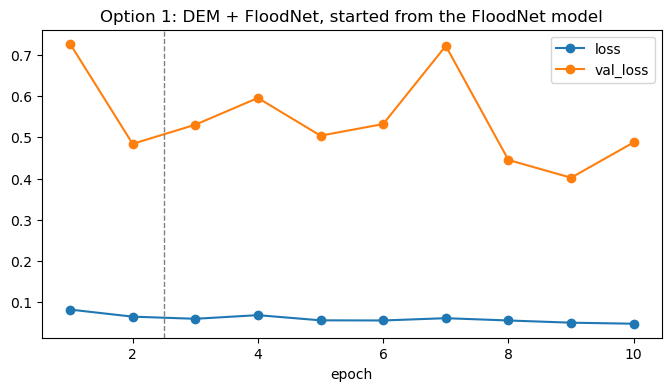

In [14]:
transfer_log = []
best_val = np.inf
for epoch in range(TRANSFER_EPOCHS):
    train_ds, steps = make_train_ds(epoch)
    h = transfer_model.fit(train_ds, validation_data=val_ds, epochs=1, steps_per_epoch=steps, verbose=0)
    loss, val_loss = h.history["loss"][0], h.history["val_loss"][0]

    saved = epoch + 1 >= TRANSFER_MIN_EPOCH and val_loss < best_val
    if saved:
        best_val = val_loss
        transfer_model.save_weights(TRANSFER_PATH)
    transfer_log.append({"epoch": epoch + 1, "loss": loss, "val_loss": val_loss})
    print(f"epoch {epoch + 1:2}/{TRANSFER_EPOCHS}  loss {loss:.4f}  val_loss {val_loss:.4f}" + ("  (saved)" if saved else ""))

transfer_model.save_weights(TRANSFER_LAST_PATH)

transfer_log = pd.DataFrame(transfer_log)
ax = transfer_log.plot(x="epoch", y=["loss", "val_loss"], marker="o", figsize=(8, 4))
ax.axvline(TRANSFER_MIN_EPOCH - 0.5, color="gray", ls="--", lw=1)
ax.set_title("FloodNet weight-transfer model: DEM + FloodNet, started from the FloodNet model")
plt.show()

### 8.1 FloodNet weight-transfer model: cutoff and test scores, compared with section 5

Same rule as before: cutoff picked on val image 12, then the Houston test images are scored at that cutoff.

In [14]:
transfer_results = {}
for name, path in [("Weight-transfer, best val", TRANSFER_PATH), ("Weight-transfer, last epoch", TRANSFER_LAST_PATH)]:
    transfer_model.load_weights(path)
    cut, table = pick_cutoff(predict_probs(transfer_model, X_val_in), y_val)
    transfer_results[name] = {"cutoff": cut, "test_probs": predict_probs(transfer_model, X_test_in)}
    print(f"{name}: best cutoff on val {cut}")
    display(table.round(3))

rows = []
for name, r in [("Started from ImageNet (section 5), best val", results["best val"]),
                ("Started from ImageNet (section 5), last epoch", results["last epoch"])] + list(transfer_results.items()):
    f, d, says = iou_scores(r["test_probs"], y_test, r["cutoff"])
    rows.append({"model": name, "cutoff": r["cutoff"], "flood IoU": f, "dry IoU": d, "mean IoU": (f + d) / 2, "says flood": says})
pd.DataFrame(rows).set_index("model").round(3)

/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Weight-transfer, best val: best cutoff on val 0.8


,cutoff,flood IoU,dry IoU,mean IoU,says flood
0,0.3,0.617,0.357,0.487,0.820
1,0.4,0.647,0.438,0.542,0.778
2,0.5,0.690,0.543,0.617,0.722
3,0.6,0.740,0.649,0.694,0.662
4,0.7,0.797,0.754,0.776,0.595
5,0.8,0.836,0.822,0.829,0.533


/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Weight-transfer, last epoch: best cutoff on val 0.8


,cutoff,flood IoU,dry IoU,mean IoU,says flood
0,0.3,0.602,0.312,0.457,0.844
1,0.4,0.619,0.362,0.491,0.818
2,0.5,0.641,0.425,0.533,0.784
3,0.6,0.679,0.522,0.601,0.731
4,0.7,0.734,0.644,0.689,0.658
5,0.8,0.800,0.768,0.784,0.569


,cutoff,flood IoU,dry IoU,mean IoU,says flood
model,,,,,
"Started from ImageNet (section 5), best val",0.8,0.720,0.454,0.587,0.635
"Started from ImageNet (section 5), last epoch",0.7,0.696,0.422,0.559,0.629
"Weight-transfer, best val",0.8,0.719,0.431,0.575,0.657
"Weight-transfer, last epoch",0.8,0.717,0.427,0.572,0.659


In [15]:
# Per Houston test image: section 5 model vs the FloodNet weight-transfer model (both best-val weights)
transfer_model.load_weights(TRANSFER_PATH)
TRANSFER_CUTOFF = transfer_results["Weight-transfer, best val"]["cutoff"]
model.load_weights(WEIGHTS_PATH)

rows = []
for i in SPLITS["test"]:
    Xi, yi = get_tiles([i])
    Xi = preprocess(Xi)
    f0, d0, _ = iou_scores(predict_probs(model, Xi), yi, CUTOFF)
    f1, d1, _ = iou_scores(predict_probs(transfer_model, Xi), yi, TRANSFER_CUTOFF)
    rows.append({"image": i, "label says flood": (yi[yi != -1] == 1).mean(),
                 "flood IoU (ImageNet start)": f0, "flood IoU (weight-transfer)": f1,
                 "mean IoU (ImageNet start)": (f0 + d0) / 2, "mean IoU (weight-transfer)": (f1 + d1) / 2})
pd.DataFrame(rows).set_index("image").round(3)

/home/jdcont/miniconda3/envs/tflabsfall24/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,label says flood,flood IoU (ImageNet start),flood IoU (weight-transfer),mean IoU (ImageNet start),mean IoU (weight-transfer)
image,,,,,
4,0.976,0.821,0.868,0.469,0.492
5,0.994,0.948,0.969,0.524,0.558
6,1.000,0.479,0.487,0.239,0.244
7,0.370,0.634,0.613,0.661,0.629
10,0.641,0.849,0.863,0.813,0.817
11,0.858,0.822,0.780,0.619,0.575


In [16]:
# Does the FloodNet weight-transfer model use the DEM? Score the test images again with the DEM zeroed.
X_test_nodem = X_test_in.copy()
X_test_nodem[..., 3] = 0
rows = []
for name, X in [("with DEM", X_test_in), ("DEM zeroed", X_test_nodem)]:
    f, d, says = iou_scores(predict_probs(transfer_model, X), y_test, TRANSFER_CUTOFF)
    rows.append({"input": name, "flood IoU": f, "dry IoU": d, "says flood": says})
del X_test_nodem
pd.DataFrame(rows).set_index("input").round(3)

,flood IoU,dry IoU,says flood
input,,,
with DEM,0.719,0.431,0.657
DEM zeroed,0.686,0.342,0.690
